In [1]:
import pandas as pd
import datetime

from config import RESSERENO_ROOT
from data_cleaning_qualtrics import create_associations_valence_df, get_trimmed_df
from bfmn_building import pipeline_multiple_participants
from tfmn_building import tfmn_building

In [12]:
pd.set_option("display.max_colwidth", None)

In [2]:
path_data = RESSERENO_ROOT / "data"

In [3]:
raw_data = pd.read_csv(f"{path_data}/0203_school_intervention.csv")

In [4]:
data_teachers = get_trimmed_df(
    raw_data, date=datetime.date(2026, 3, 2), participant_label="teacher"
)

In [23]:
text_df = pd.DataFrame(data_teachers[["participant_id", "Q18"]])
text_df = text_df.rename(columns={"Q18": "text"})
# convert to string in lower case, remove trailing punctuation/whitespace, then add a full stop
text_df["text"] = text_df["text"].str.lower().str.rstrip(".!? \n\t") + "."

In [7]:
associations_valences_teachers = create_associations_valence_df(raw_data)

In [21]:
keywords_bfmn = [
    "intelligenza artificiale",
    "chatgpt",
    "matematica",
    "fisica",
    "scienza",
]

Number of unique words: 835


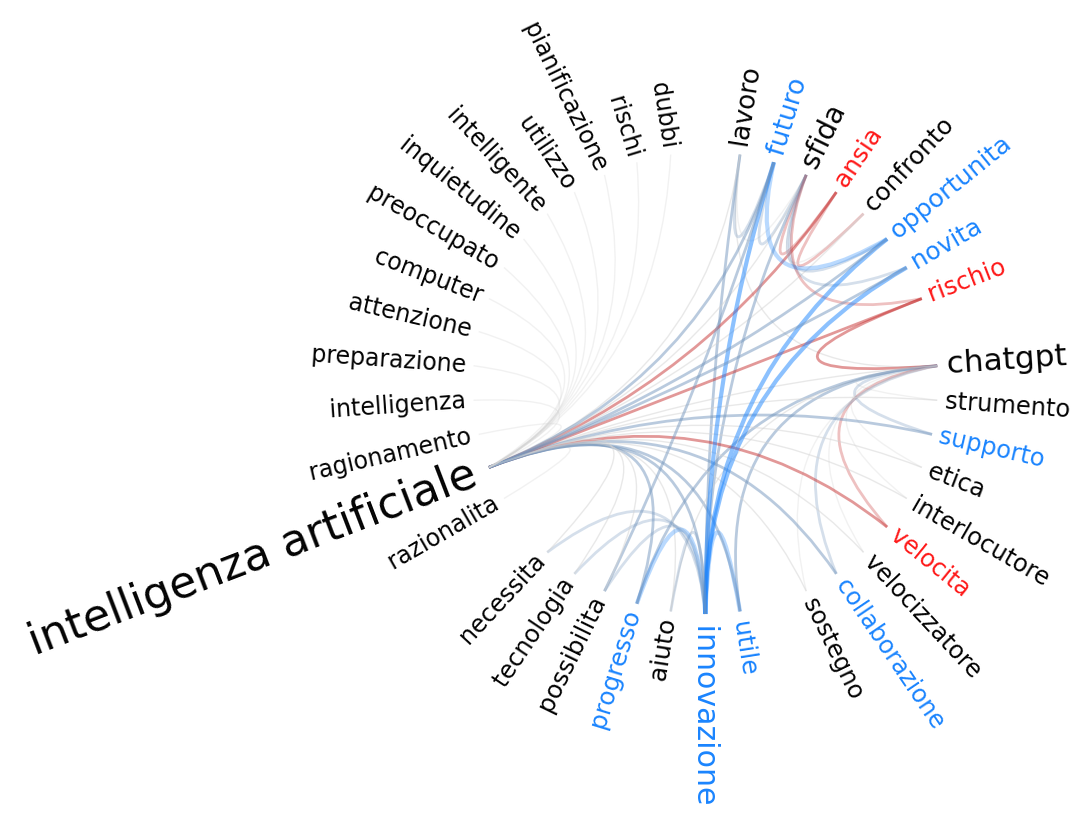

Local clustering intelligenza artificiale: 0.052552552552552555
Degree intelligenza artificiale: 37
Counts of 'intelligenza artificiale' = {'positive': 8, 'negative': 3, 'neutral': 27}
Mode of 'intelligenza artificiale' = neutral


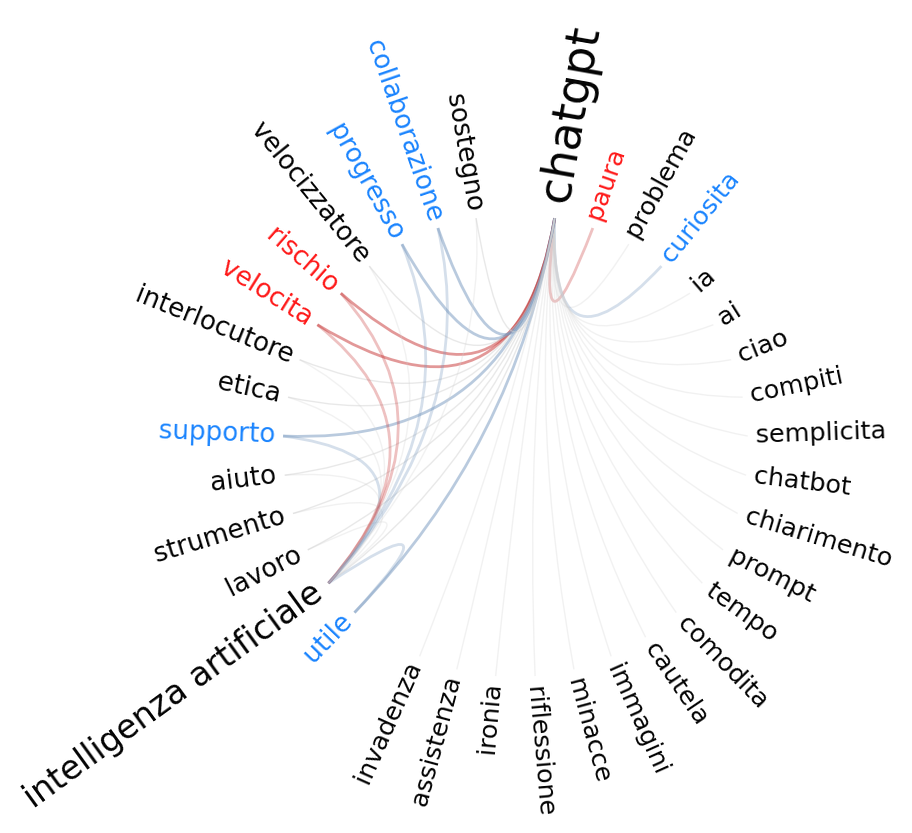

Local clustering chatgpt: 0.023172905525846704
Degree chatgpt: 34
Counts of 'chatgpt' = {'positive': 5, 'negative': 3, 'neutral': 27}
Mode of 'chatgpt' = neutral


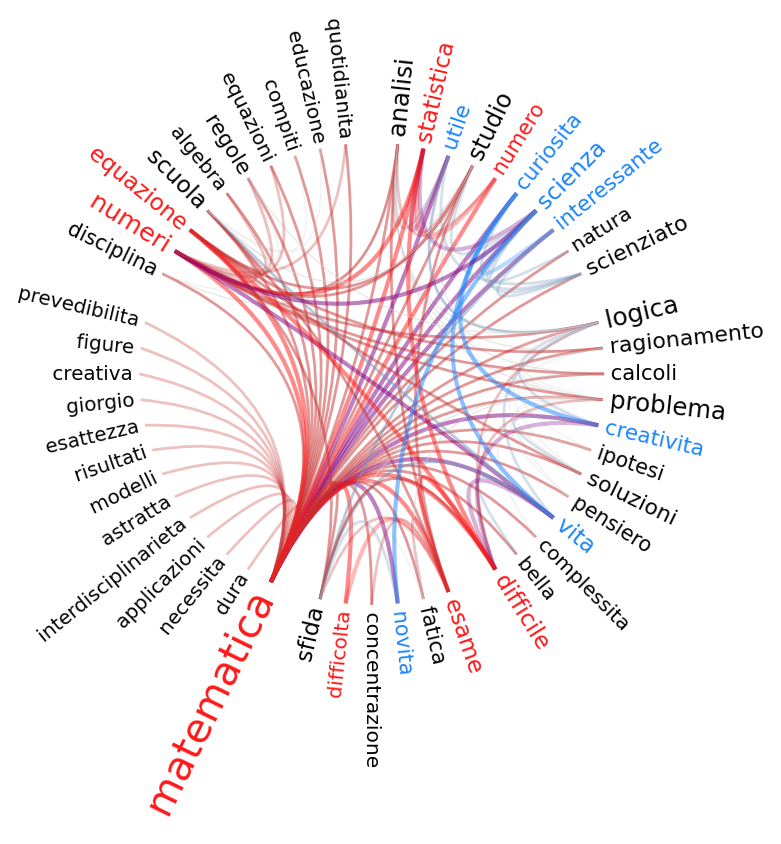

Local clustering matematica: 0.07265306122448979
Degree matematica: 50
Counts of 'matematica' = {'positive': 7, 'negative': 8, 'neutral': 36}
Mode of 'matematica' = neutral


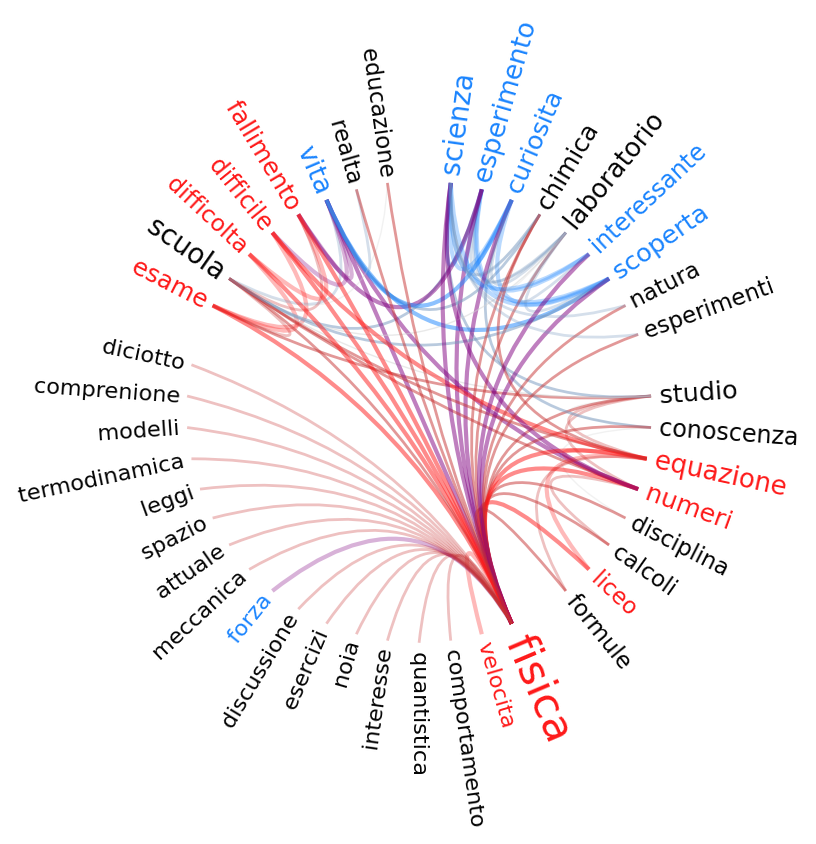

Local clustering fisica: 0.06463414634146342
Degree fisica: 41
Counts of 'fisica' = {'positive': 7, 'negative': 9, 'neutral': 26}
Mode of 'fisica' = neutral


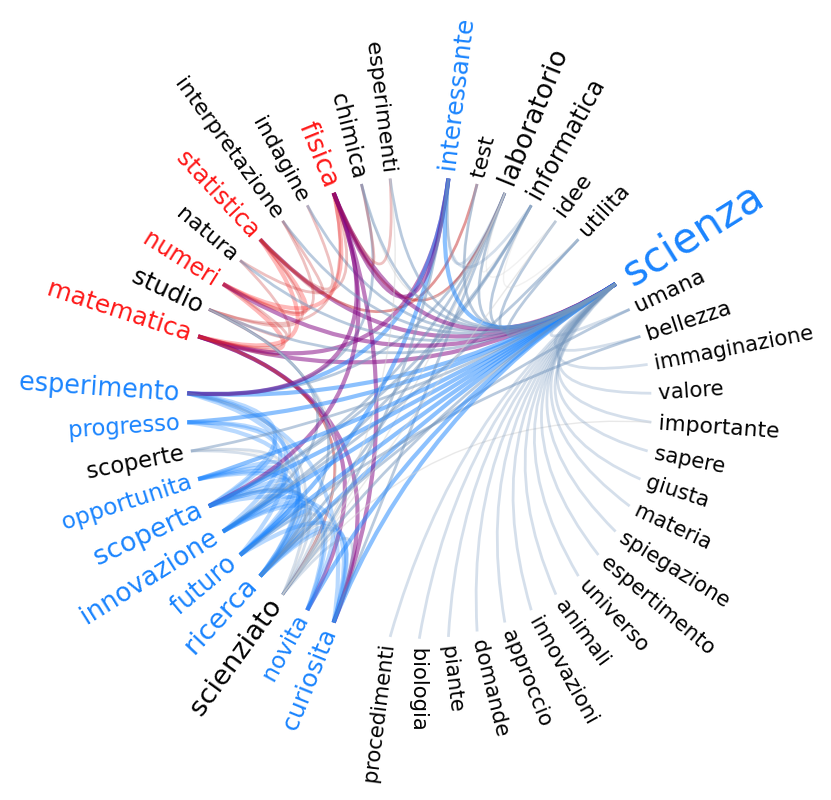

Local clustering scienza: 0.08383838383838384
Degree scienza: 45
Counts of 'scienza' = {'positive': 11, 'negative': 4, 'neutral': 31}
Mode of 'scienza' = neutral


In [ ]:
final_df, G, fmn, features_fmnt_df = pipeline_multiple_participants(
    df=associations_valences_teachers,
    keywords=keywords_bfmn,
    folder_path=RESSERENO_ROOT,
    file_path="school_intervention",
    flower="no",
)

In [ ]:
keywords_tfmn = ["matematica", "ansia", "sfida", "difficoltà"]

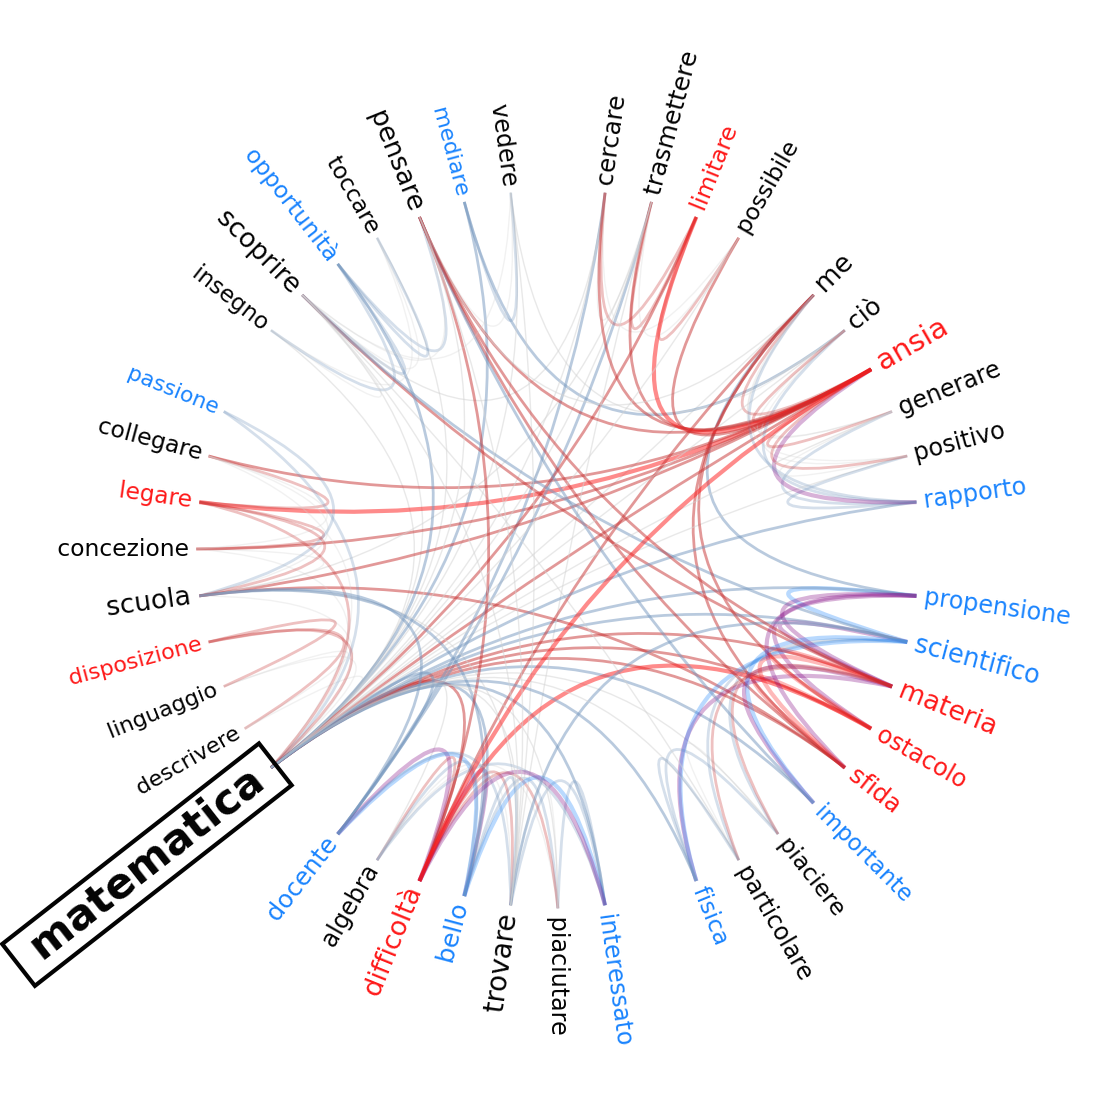

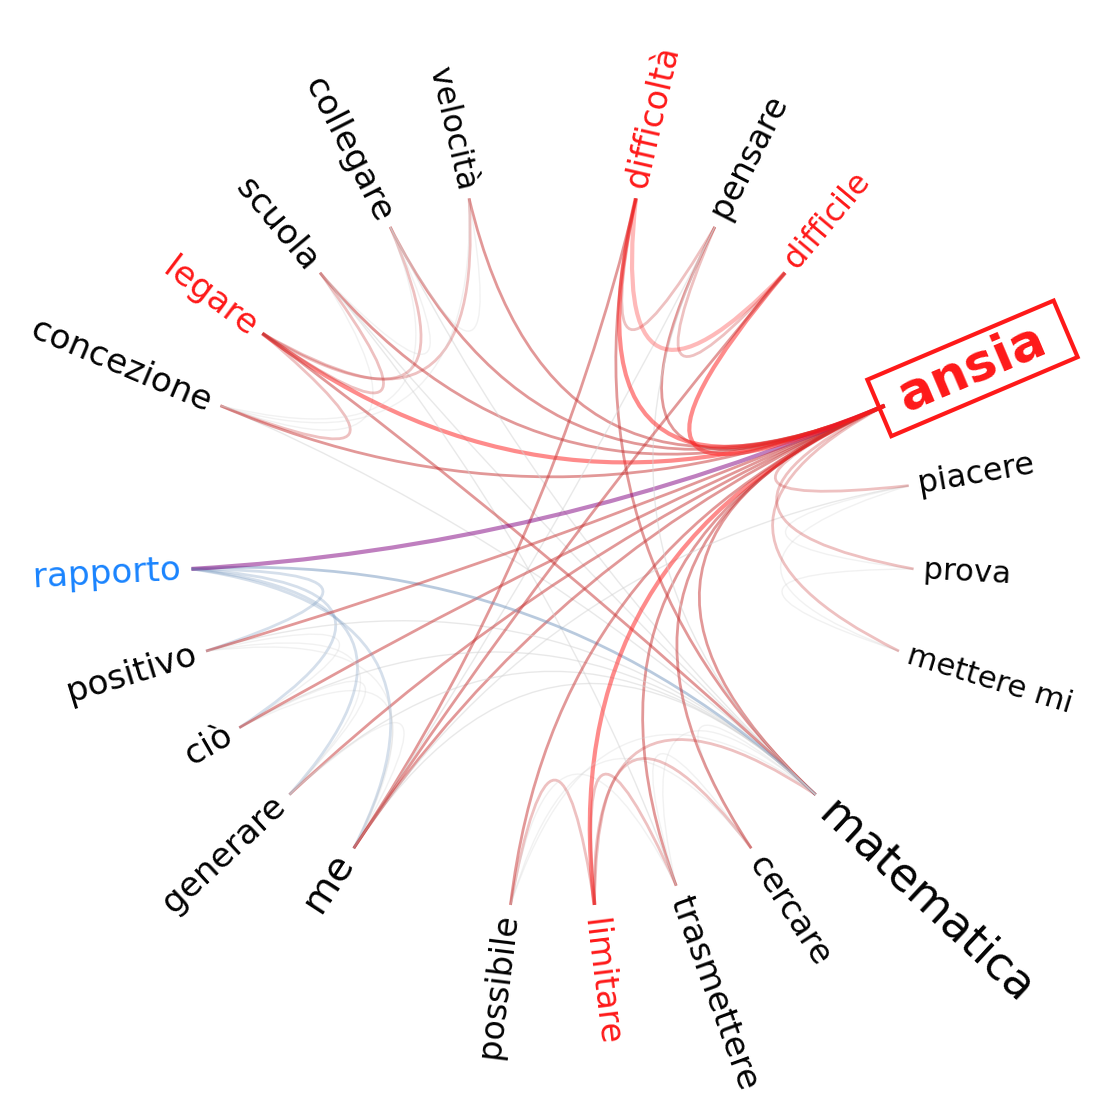

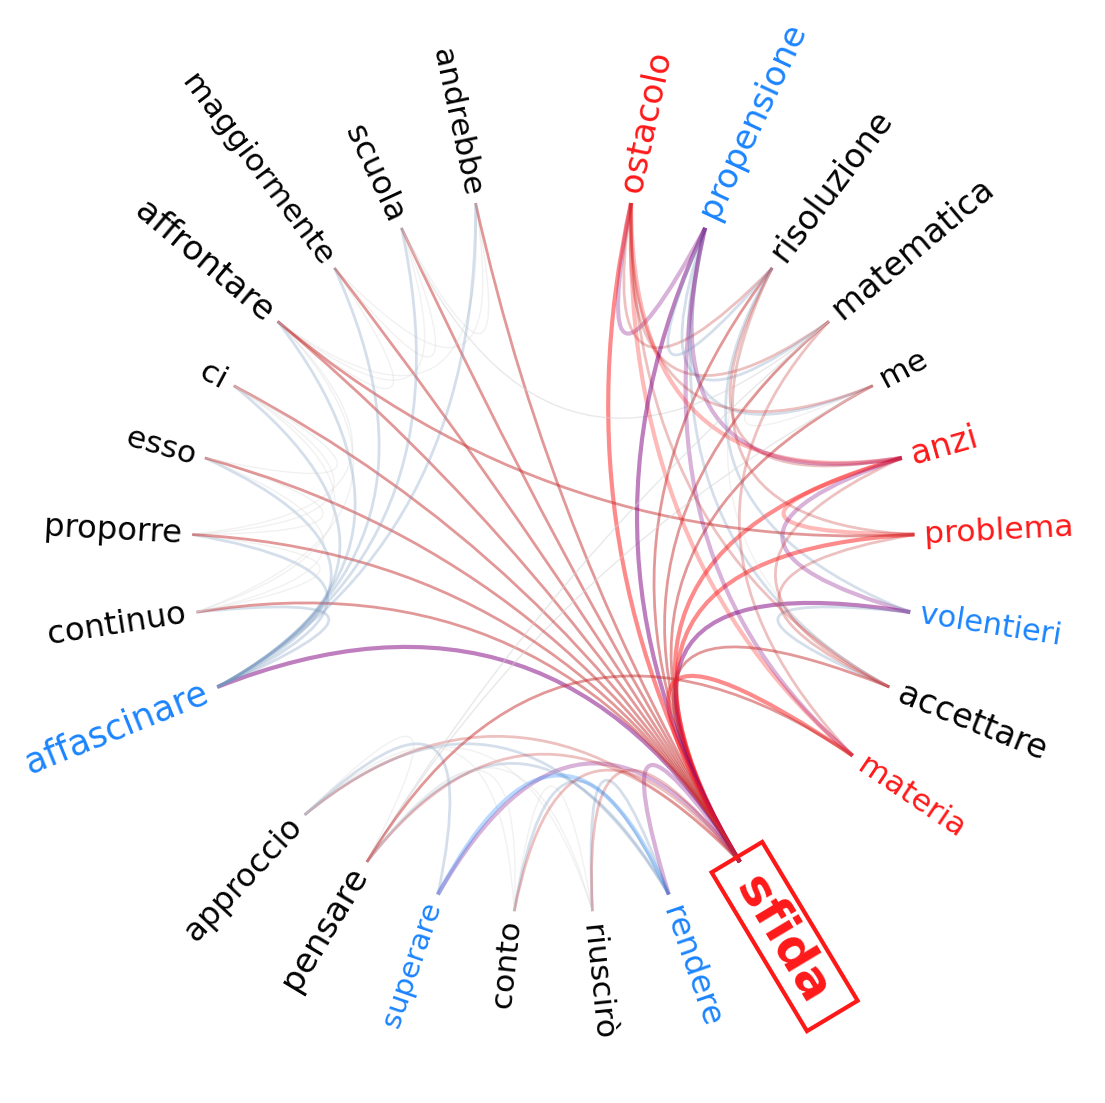

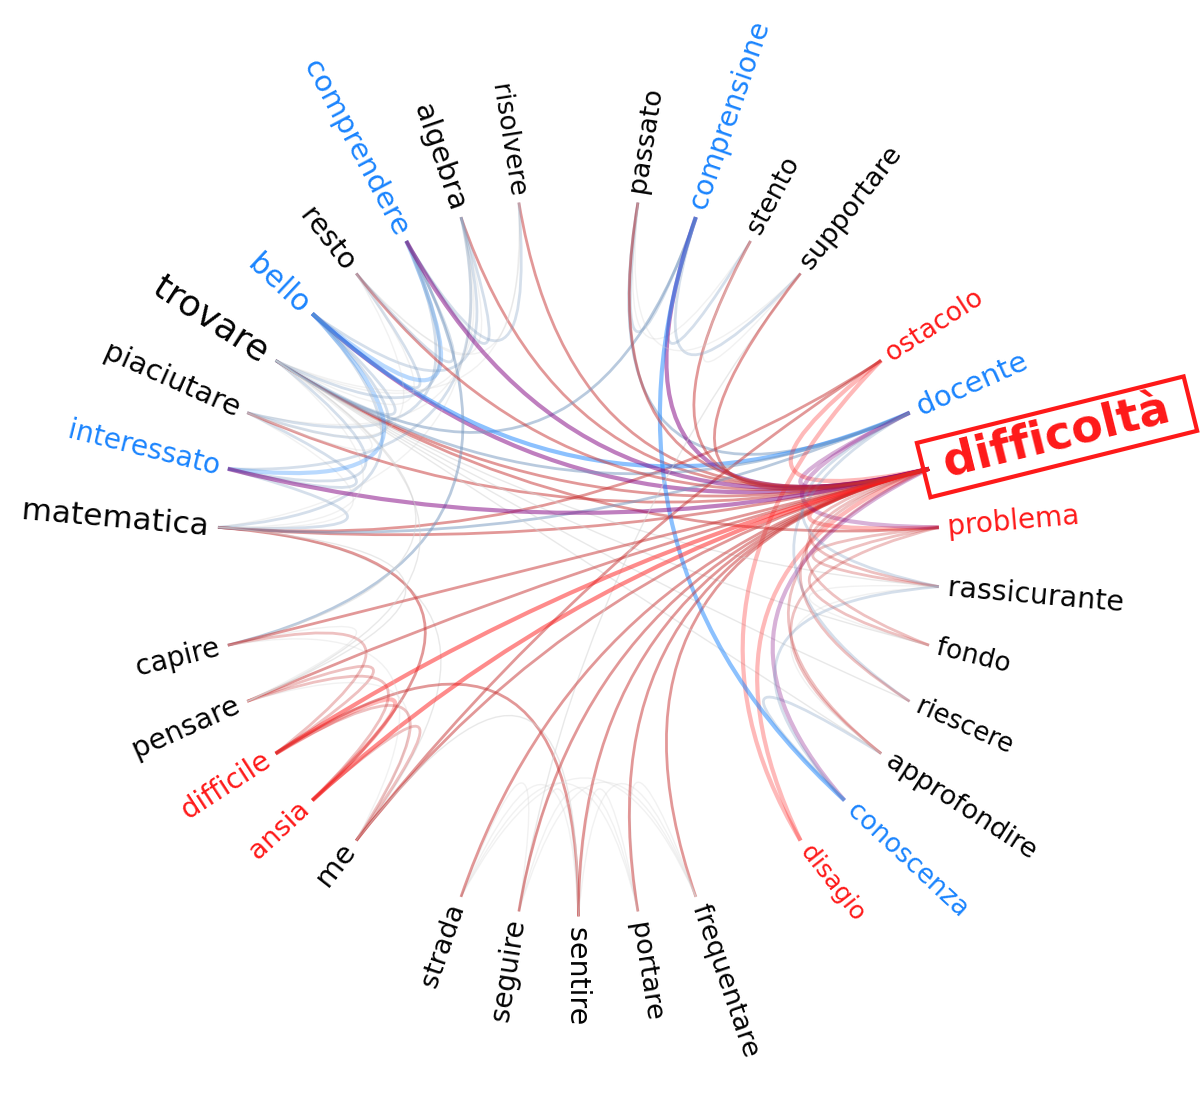

⚠️ Skipping 'numeri' of school_intervention sample: min() iterable argument is empty.


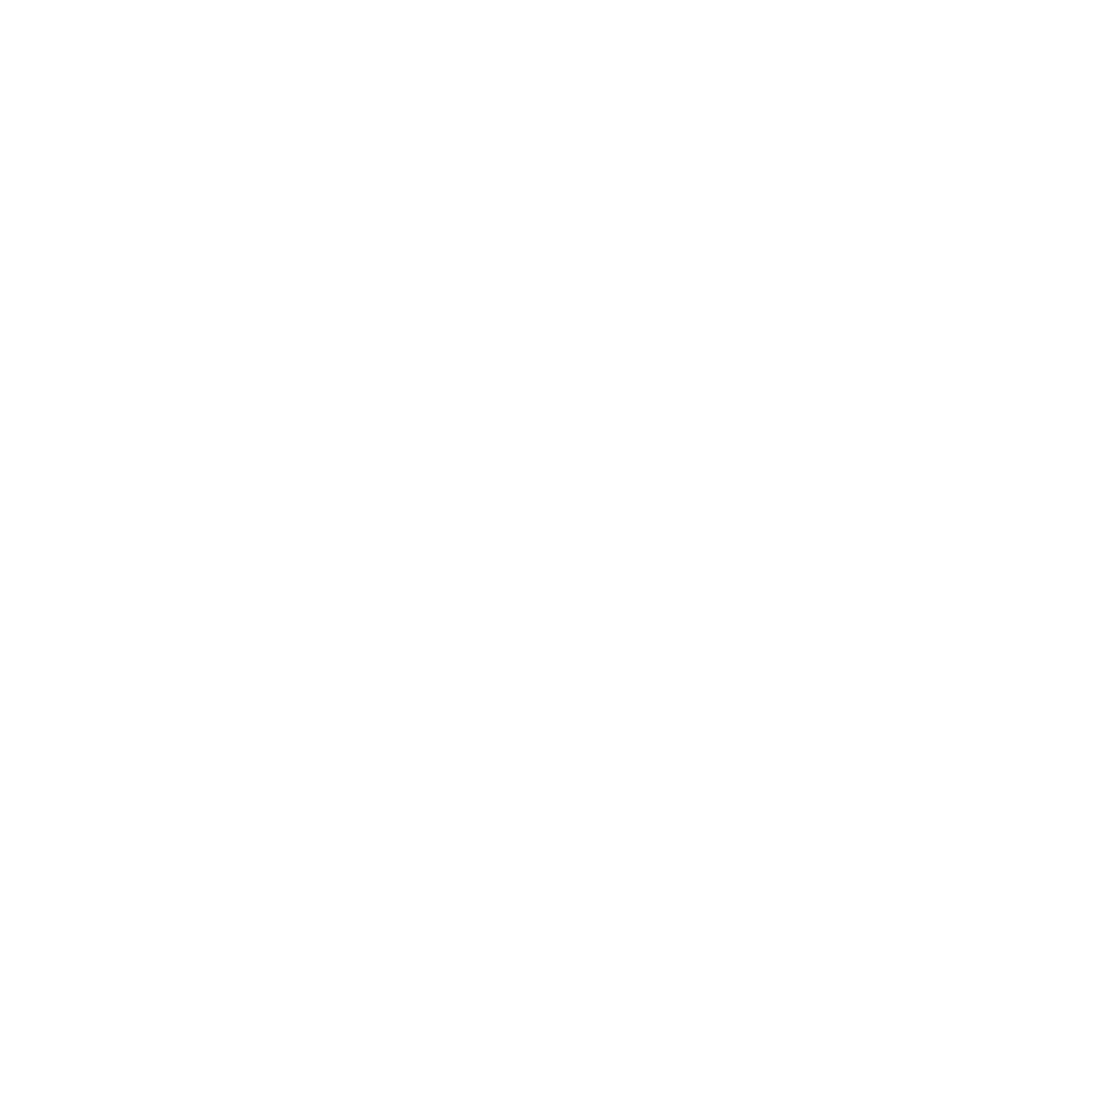

In [20]:
tfmn_building(
    text_df, keywords_tfmn, RESSERENO_ROOT, "school_intervention", flower="no"
)